In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import  r2_score
import jdatetime

In [3]:
pd.set_option('display.max_columns', None)

In [4]:
data = pd.read_csv('../gift project for data analyst/bama.csv')
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 56267 entries, 0 to 56266
Data columns (total 20 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   url                        56267 non-null  str    
 1   title                      56198 non-null  str    
 2   price                      56198 non-null  str    
 3   year                       56198 non-null  float64
 4   address                    56198 non-null  str    
 5   external_information       52492 non-null  str    
 6   authentication_status      54146 non-null  str    
 7   description                47885 non-null  str    
 8   mileage                    56198 non-null  str    
 9   fuel_type                  56198 non-null  str    
 10  transmission               56197 non-null  str    
 11  body_condition             56197 non-null  str    
 12  body_color                 56197 non-null  str    
 13  interior_color             56197 non-null  str    
 14  e

C:\Users\SarayeTel\AppData\Local\Temp\ipykernel_132\2093948610.py:1: DtypeWarning: Columns (0: error) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv('../gift project for data analyst/bama.csv')


In [5]:
for i in data.columns:
    if not data[i].isnull().sum() == 0:
        print (i)

title
price
year
address
external_information
authentication_status
description
mileage
fuel_type
transmission
body_condition
body_color
interior_color
engine_capacity
powertrain
acceleration
combined_fuel_consumption
error


<br><br>

## Data Cleaning & Missing Values Handling

In [6]:
data = data.query('title.notnull()')
data = data.query('error.isnull()')
data = data.query('transmission.notnull()')

In [7]:
data['engine_capacity'] = data['engine_capacity'].str.replace('لیتر', '')
data['engine_capacity'] = pd.to_numeric(data['engine_capacity'], errors='coerce')
data['acceleration'] = data['acceleration'].str.replace('ثانیه', '')
data['acceleration'] = pd.to_numeric(data['acceleration'], errors='coerce')
data['combined_fuel_consumption'] = data['combined_fuel_consumption'].str.replace('لیتر در صد کیلومتر', '')
data['combined_fuel_consumption'] = pd.to_numeric(data['combined_fuel_consumption'], errors='coerce')

data = data.rename(columns={'engine_capacity':'engine_capacity(By Liter)',
                    'acceleration':'acceleration(By Second)',
                    'combined_fuel_consumption':'combined_fuel_consumption(By Liter Per Kilometers)'})

In [8]:
data['year'] = data['year'].astype(int)
data['authentication_status'] = data['authentication_status'].fillna('not_authenticated')
data = data.drop(columns=['url','external_information','description','scraped_at','error'])

In [9]:
data['interior_color'] = data['interior_color'].str.replace('داخل','')

In [10]:
data['price'] = data['price'].replace('توافقی', np.nan)
data['price'] = pd.to_numeric(data['price'], errors='coerce')

fill_price = data.groupby('title')['price'].transform('mean')
data['price'] = data['price'].fillna(fill_price)
data['price'] = data['price'].fillna(data['price'].mean())
data['price'] = data['price'].astype(int)

In [11]:
data['mileage'] = data['mileage'].replace('صفر کیلومتر', '0 km')
data['mileage'] = data['mileage'].str.replace('km', '')
data['mileage'] = data['mileage'].str.replace(',', '')
data['mileage'] = data['mileage'].replace('کار کرده', np.nan)

data['mileage'] = pd.to_numeric(data['mileage'], errors='coerce')
data['mileage'] = data['mileage'].fillna(data['mileage'].mean())
data['mileage'] = data['mileage'].astype(int)

data = data.rename(columns={'mileage':'mileage(By km)'})

In [12]:
mode_powertrain = data.groupby('title')['powertrain'].transform(
    lambda x: x.mode()[0] if not x.mode().empty else None)
data['powertrain'] = data['powertrain'].fillna(data['title'].map(mode_powertrain))
data['powertrain'] = data['powertrain'].fillna('نامشخص').astype(str)

In [13]:
def change_to_shamsi(year):
    if year > 1900:
        return year - 621
    else:
        return year
    
data ['year'] = data['year'].apply(change_to_shamsi)

### *Advanced ML Techniques for Missing Value Imputation* 

In [14]:
encoded_data = pd.get_dummies(data, columns=['title','address','authentication_status',
                            'fuel_type','transmission','body_condition','body_color',
                            'interior_color','powertrain'], dtype=int)

In [15]:
# engine capacity column
known_data = encoded_data.query('`engine_capacity(By Liter)`.notnull()')
unknown_data = encoded_data.query('`engine_capacity(By Liter)`.isnull()')

features = known_data.drop(columns=['engine_capacity(By Liter)'])
label = known_data['engine_capacity(By Liter)']

X_train , X_test , y_train , y_test = train_test_split(features, label, test_size = 0.2, random_state = 40)

In [16]:
model_predict_engine_capacity = HistGradientBoostingRegressor(random_state=1)
model_predict_engine_capacity.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",1
,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'squared_error'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",100
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


In [17]:
y_model = model_predict_engine_capacity.predict(X_test)
r2_score(y_test, y_model).__round__(2)

0.99

In [18]:
predicted_values = model_predict_engine_capacity.predict(unknown_data.drop(columns=['engine_capacity(By Liter)'])).round(2)
data.loc[unknown_data.index, 'engine_capacity(By Liter)'] = predicted_values

In [19]:
# acceleration column
known_data = encoded_data.query('`acceleration(By Second)`.notnull()')
unknown_data = encoded_data.query('`acceleration(By Second)`.isnull()')

In [20]:
features = known_data.drop(columns=['acceleration(By Second)'])
label = known_data['acceleration(By Second)']
X_train , X_test , y_train , y_test = train_test_split(features, label, test_size = 0.2, random_state = 40)

In [21]:
model_predict_acceleration = HistGradientBoostingRegressor(random_state=1)
model_predict_acceleration.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",1
,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'squared_error'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",100
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


In [22]:
y_model = model_predict_acceleration.predict(X_test)
r2_score(y_test, y_model).__round__(2)

0.98

In [23]:
predicted_values = model_predict_acceleration.predict(unknown_data.drop(columns=['acceleration(By Second)'])).round(2)
data.loc[unknown_data.index, 'acceleration(By Second)'] = predicted_values

In [24]:
# combined fuel consumption
known_data = encoded_data.query('`combined_fuel_consumption(By Liter Per Kilometers)`.notnull()')
unknown_data = encoded_data.query('`combined_fuel_consumption(By Liter Per Kilometers)`.isnull()')

In [25]:
features = known_data.drop(columns=['combined_fuel_consumption(By Liter Per Kilometers)'])
label = known_data['combined_fuel_consumption(By Liter Per Kilometers)']
X_train , X_test , y_train , y_test = train_test_split(features, label, test_size = 0.2, random_state = 40)

In [26]:
model_predict_combined_fuel_consumption = HistGradientBoostingRegressor(random_state=1)
model_predict_combined_fuel_consumption.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",1
,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'squared_error'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",100
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


In [27]:
y_model = model_predict_combined_fuel_consumption.predict(X_test)
r2_score(y_test, y_model).__round__(2)

0.98

In [28]:
predicted_values = model_predict_combined_fuel_consumption.predict(unknown_data.drop(columns=['combined_fuel_consumption(By Liter Per Kilometers)'])).round(2)
data.loc[unknown_data.index, 'combined_fuel_consumption(By Liter Per Kilometers)'] = predicted_values


To handle missing values in technical specs without losing data variance, we trained a **HistGradientBoostingRegressor** for each of the following features:

### Imputation Pipeline
1. **Model:** `HistGradientBoostingRegressor` (optimized for speed & accuracy).
2. **Strategy:** Using vehicle attributes (like Title, Fuel Type, Transmission) as features to predict missing values.
3. **Validation:** Evaluating model performance via $R^2$ score before applying to the dataset.

### Applied Features
- **Engine Capacity :** Predicted using powertrain and body attributes.
- **Acceleration :** Predicted based on engine size and transmission performance.
- **Fuel Consumption :** Predicted based on engine displacement and technical specs.

> **Note:** Predictive imputation provides significantly more realistic values compared to simple mean/median filling.


In [29]:
data.info()

<class 'pandas.DataFrame'>
Index: 56197 entries, 0 to 56266
Data columns (total 15 columns):
 #   Column                                              Non-Null Count  Dtype  
---  ------                                              --------------  -----  
 0   title                                               56197 non-null  str    
 1   price                                               56197 non-null  int64  
 2   year                                                56197 non-null  int64  
 3   address                                             56197 non-null  str    
 4   authentication_status                               56197 non-null  str    
 5   mileage(By km)                                      56197 non-null  int64  
 6   fuel_type                                           56197 non-null  str    
 7   transmission                                        56197 non-null  str    
 8   body_condition                                      56197 non-null  str    
 9   body_color 

<br><br>

## Outlier Handling

In [30]:
sns.set_theme(style="whitegrid")

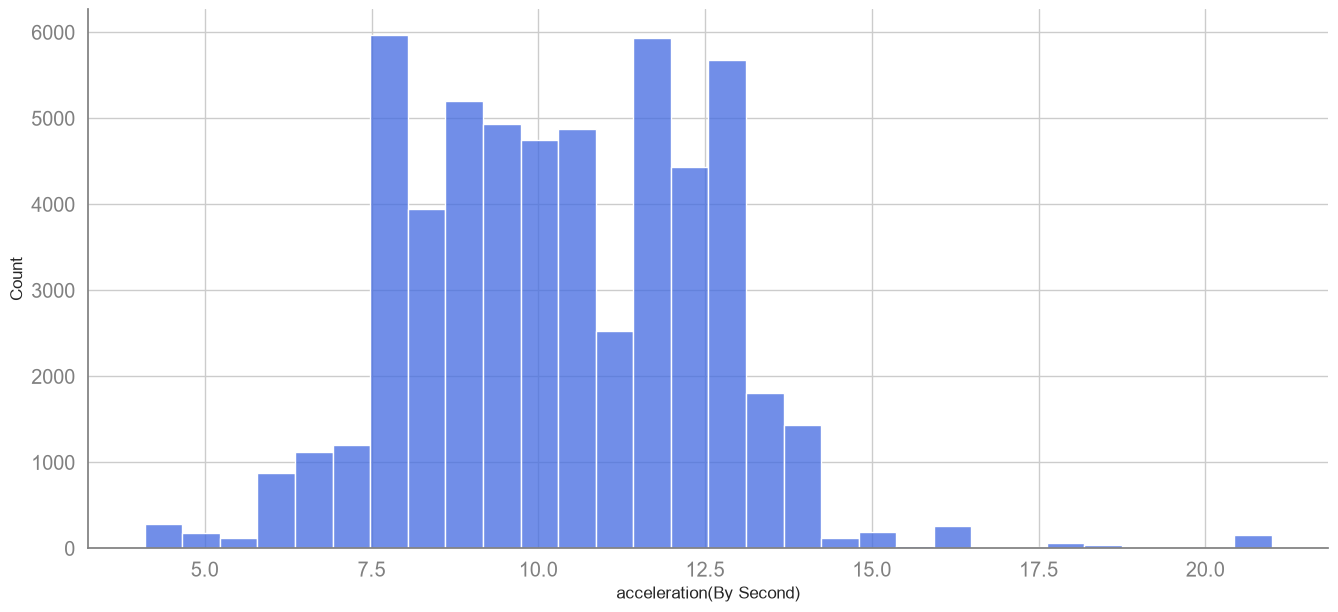

In [31]:
fig , ax = plt.subplots(figsize=(16,7))

sns.histplot(
    data=data,
    x="acceleration(By Second)",
    bins=30,  
    color="royalblue",
)

ax.spines[["right", "top"]].set_visible(False)
ax.spines[['left', 'bottom']].set_color('gray')

ax.tick_params(axis="x", colors="gray", labelsize="large")
ax.tick_params(axis="y", colors="gray", labelsize="large")

plt.show()

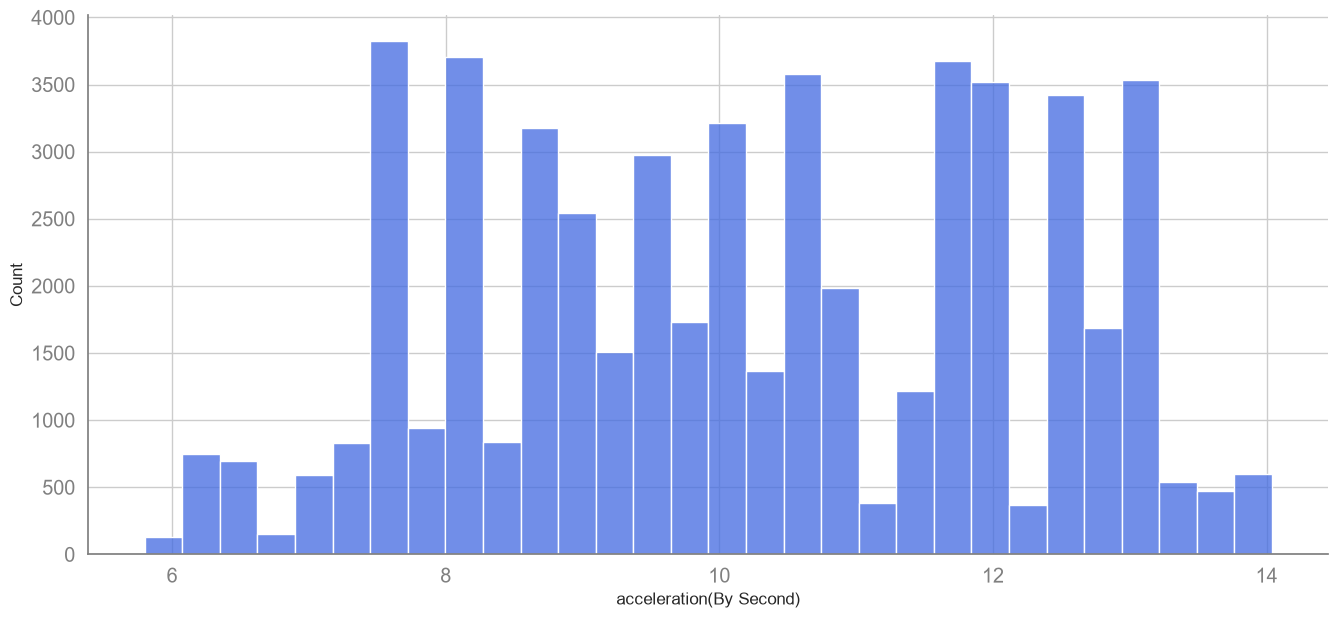

In [32]:
fig , ax = plt.subplots(figsize=(16,7))

outlier_cut_off_point_up_acceleration = np.percentile(data['acceleration(By Second)'], q=98)
outlier_cut_off_point_down_acceleration = np.percentile(data['acceleration(By Second)'], q=1)
sns.histplot(
    data=data.query('(`acceleration(By Second)` < @outlier_cut_off_point_up_acceleration) & (`acceleration(By Second)` > @outlier_cut_off_point_down_acceleration)'),
    x="acceleration(By Second)",
    bins=30, 
    color="royalblue",
)
ax.spines[["right", "top"]].set_visible(False)
ax.spines[['left', 'bottom']].set_color('gray')

ax.tick_params(axis="x", colors="gray", labelsize="large")
ax.tick_params(axis="y", colors="gray", labelsize="large")

plt.show()

In [33]:
data = data.query(' (`acceleration(By Second)` < @outlier_cut_off_point_up_acceleration) & (`acceleration(By Second)` > @outlier_cut_off_point_down_acceleration) ')

To focus on the core data distribution and avoid outlier distortion, we filtered the `acceleration` feature using percentile thresholds:

- **Upper Bound:** 98th percentile ($q=98$)
- **Lower Bound:** 1st percentile ($q=1$)

> **Data Excluded:** 
> We excluded **3%** of the data (1% from the bottom tail + 2% from the top tail) to visualize the behavior of the central 97% of the dataset.


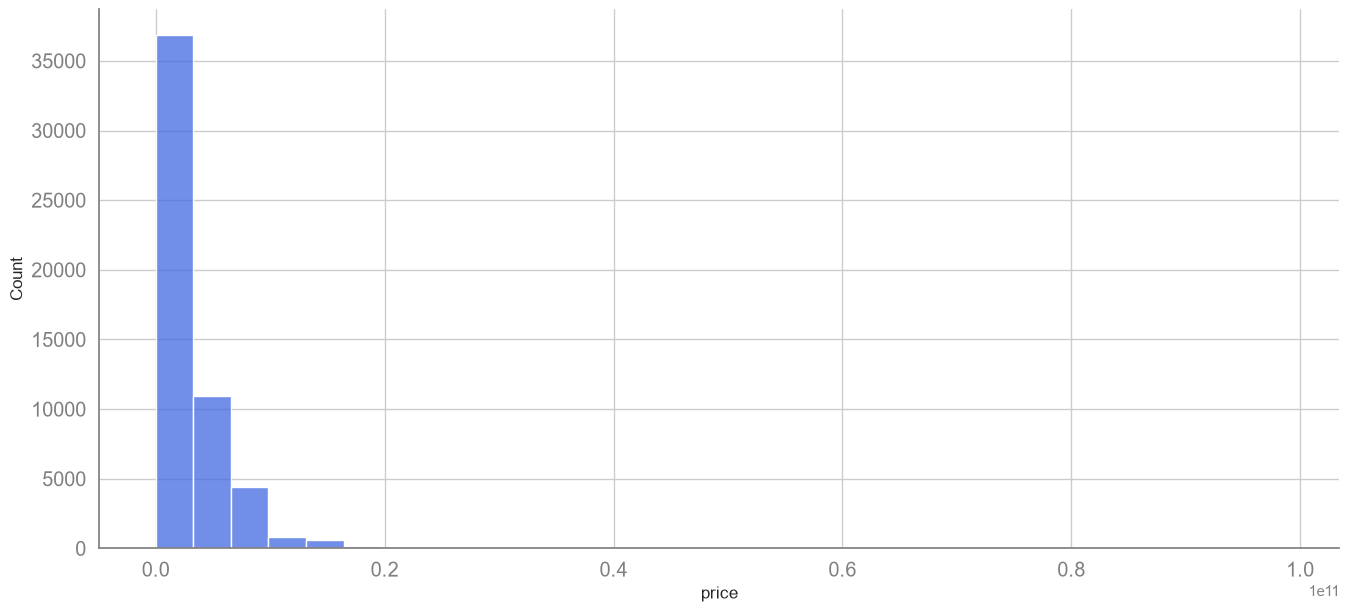

In [34]:
fig , ax = plt.subplots(figsize=(16,7))

sns.histplot(
    data=data,
    x="price",
    bins=30,  
    color="royalblue",
)

ax.spines[["right", "top"]].set_visible(False)
ax.spines[['left', 'bottom']].set_color('gray')

ax.tick_params(axis="x", colors="gray", labelsize="large")
ax.tick_params(axis="y", colors="gray", labelsize="large")

plt.show()

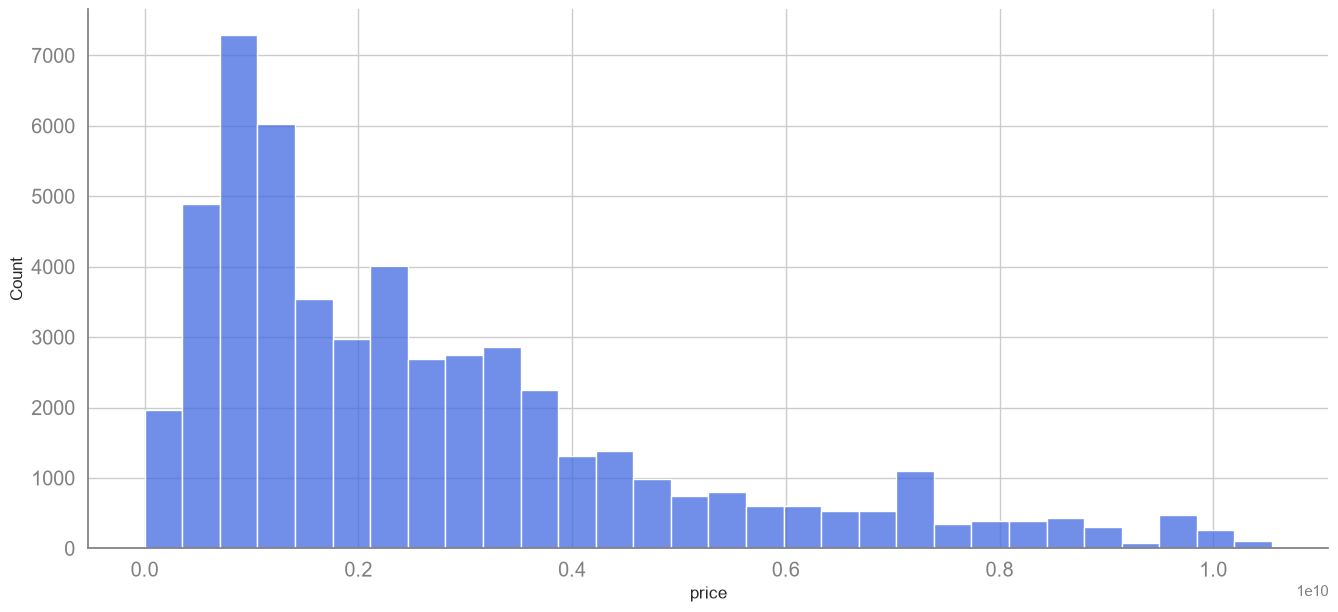

In [35]:
fig , ax = plt.subplots(figsize=(16,7))

outlier_cut_off_point_up_price = np.percentile(data['price'], q=97.5)
sns.histplot(
    data=data.query('price < @outlier_cut_off_point_up_price'),
    x="price",
    bins=30,  
    color="royalblue",
)

ax.spines[["right", "top"]].set_visible(False)
ax.spines[['left', 'bottom']].set_color('gray')

ax.tick_params(axis="x", colors="gray", labelsize="large")
ax.tick_params(axis="y", colors="gray", labelsize="large")

plt.show()

In [36]:
data = data.query('price < @outlier_cut_off_point_up_price')

To address the significant right-skewness of vehicle `prices`, we cleaned the dataset by removing extreme high-end outliers:

- **Removal Threshold:** 97.5th percentile ($q=97.5$)

> **Data Cleaning Note:**
> We removed the top **2.5%** of the most expensive vehicles from the dataset to prevent outlier distortion and ensure a cleaner, more accurate analysis of the primary price range.


In [37]:
data['mileage(By km)'].value_counts()

mileage(By km)
0         31526
49297       466
100000      308
200000      285
120000      278
          ...  
4121          1
9450          1
14750         1
1919          1
107500        1
Name: count, Length: 1342, dtype: int64

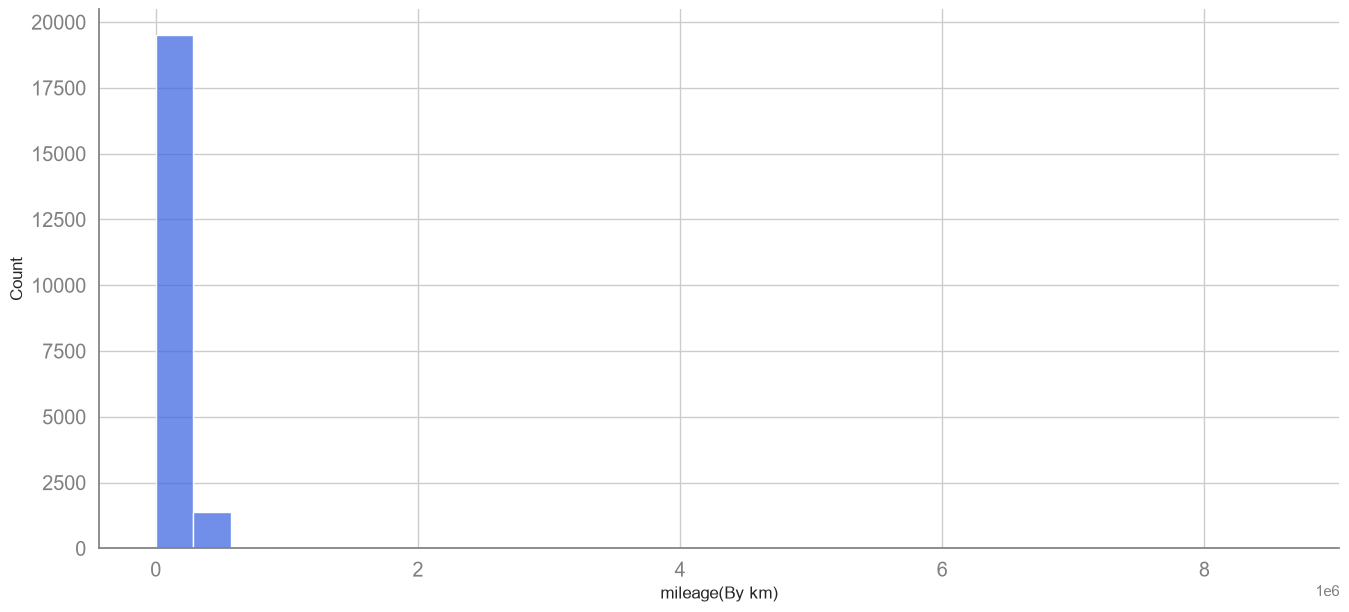

In [38]:
fig , ax = plt.subplots(figsize=(16,7))

sns.histplot(
    data=data[data['mileage(By km)'] > 1],
    x="mileage(By km)",
    bins=30,  
    color="royalblue",
)

ax.spines[["right", "top"]].set_visible(False)
ax.spines[['left', 'bottom']].set_color('gray')

ax.tick_params(axis="x", colors="gray", labelsize="large")
ax.tick_params(axis="y", colors="gray", labelsize="large")

plt.show()

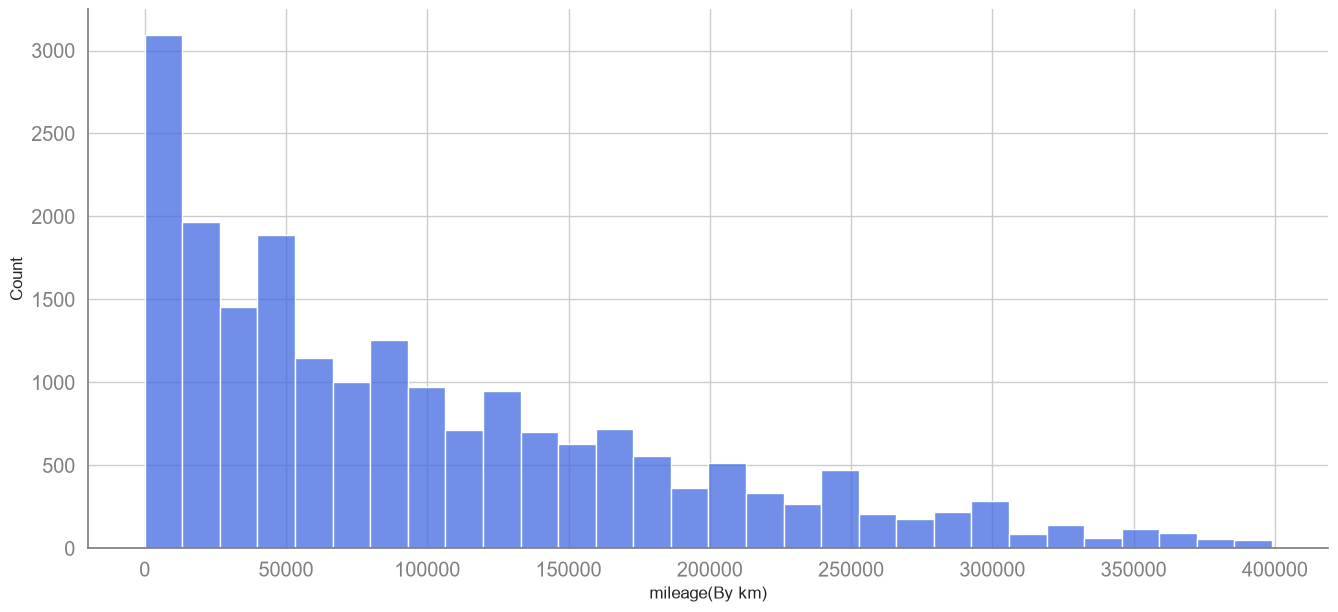

In [39]:
fig , ax = plt.subplots(figsize=(16,7))

outlier_cut_off_point_up_mileage = np.percentile(data['mileage(By km)'], q=99)
sns.histplot(
    data=data[data['mileage(By km)'] > 1].query('`mileage(By km)` < @outlier_cut_off_point_up_mileage'),
    x="mileage(By km)",
    bins=30,  
    color="royalblue",
)

ax.spines[["right", "top"]].set_visible(False)
ax.spines[['left', 'bottom']].set_color('gray')

ax.tick_params(axis="x", colors="gray", labelsize="large")
ax.tick_params(axis="y", colors="gray", labelsize="large")

plt.show()

In [40]:
data = data.query('`mileage(By km)` < @outlier_cut_off_point_up_mileage')

We processed the `mileage` data using a two-step approach to ensure both statistical accuracy and visualization clarity:

- **Data Cleaning (Outlier Removal):** Removed the top 1% of the dataset ($q=99$) as statistical outliers to maintain data integrity.
- **Visual Exclusion:** Temporarily excluded records with $\le 1$ km mileage from the plot.

> **Note:** While outliers were permanently cleaned, we filtered out the near-zero mileage vehicles specifically for this visualization. These records (brand-new/untracked cars) create an extreme density spike that masks the true distribution of the used-vehicle market.


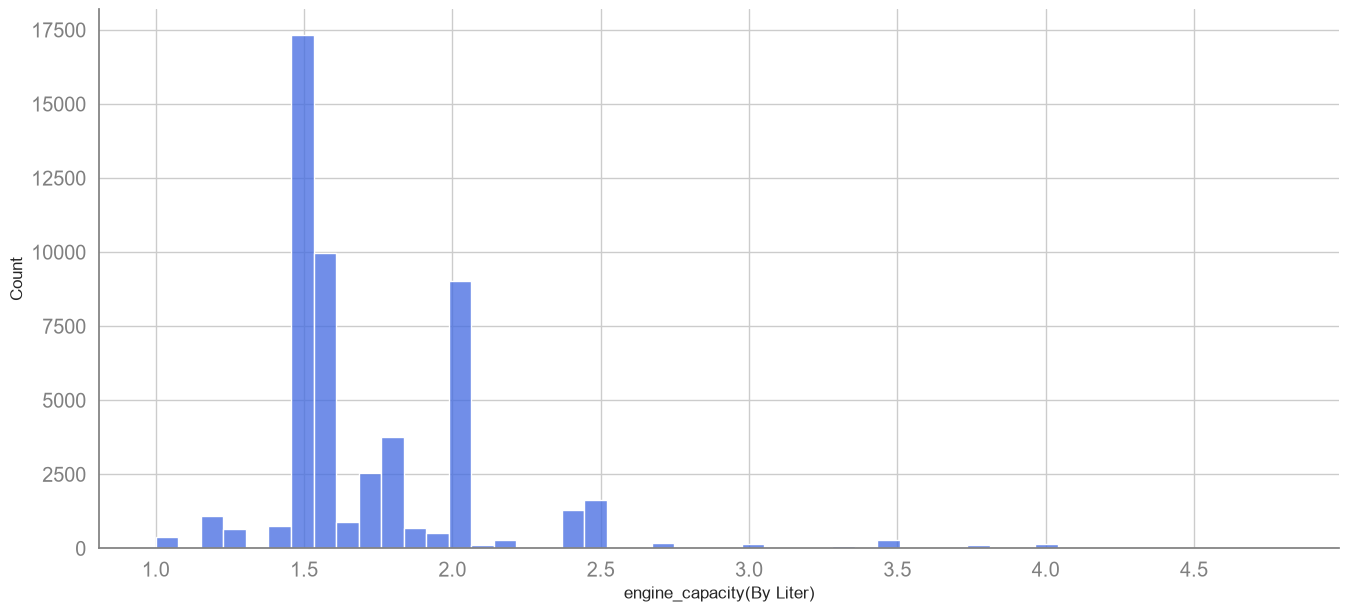

In [41]:
fig , ax = plt.subplots(figsize=(16,7))

sns.histplot(
    data=data,
    x="engine_capacity(By Liter)",
    bins=50,  
    color="royalblue",
)

ax.spines[["right", "top"]].set_visible(False)
ax.spines[['left', 'bottom']].set_color('gray')

ax.tick_params(axis="x", colors="gray", labelsize="large")
ax.tick_params(axis="y", colors="gray", labelsize="large")

plt.show()

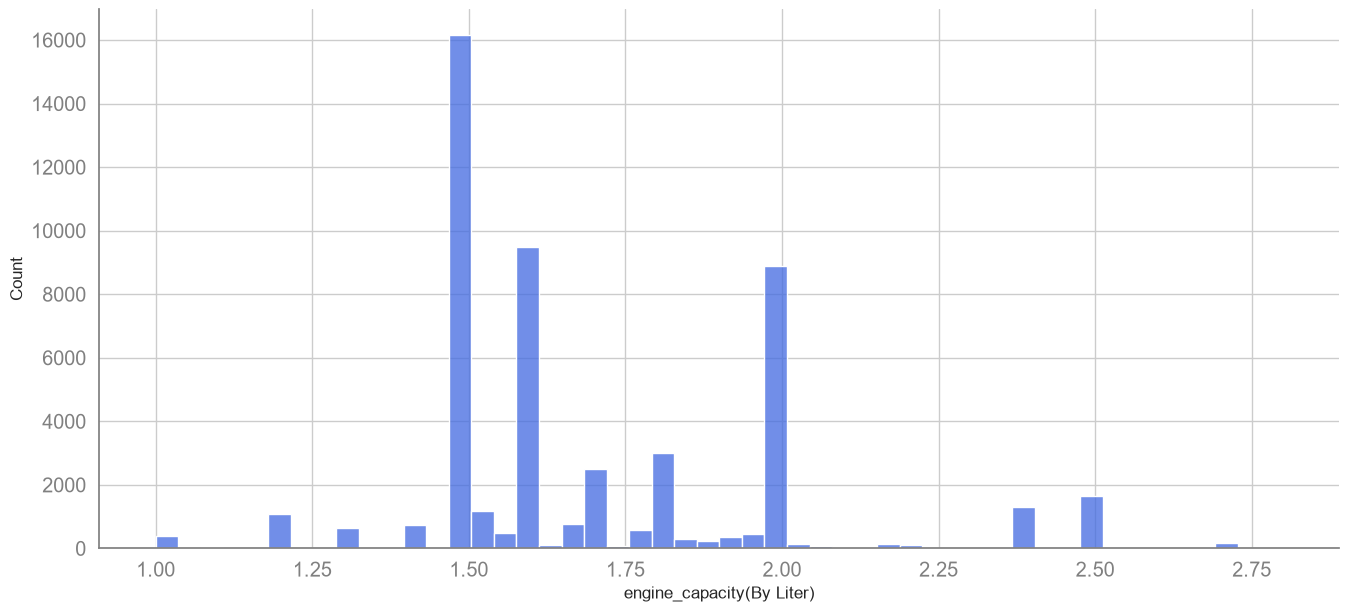

In [42]:
fig , ax = plt.subplots(figsize=(16,7))

outlier_cut_off_point_up_engine_capacity = np.percentile(data['engine_capacity(By Liter)'], q=98.5)

sns.histplot(
    data=data.query('(`engine_capacity(By Liter)` < @outlier_cut_off_point_up_engine_capacity)'),
    x="engine_capacity(By Liter)",
    bins=50,  
    color="royalblue",
)

ax.spines[["right", "top"]].set_visible(False)
ax.spines[['left', 'bottom']].set_color('gray')

ax.tick_params(axis="x", colors="gray", labelsize="large")
ax.tick_params(axis="y", colors="gray", labelsize="large")

plt.show()

In [43]:
data = data.query('(`engine_capacity(By Liter)` < @outlier_cut_off_point_up_engine_capacity)')

To ensure accurate analysis of the standard `engine capacity` range, we cleaned the dataset by removing extreme high-end outliers:

- **Outlier Removal Threshold:** 98.5th percentile ($q=98.5$)
- **Resolution:** 50 bins (to capture discrete engine displacement peaks).

> **Data Cleaning Note:**
> We removed the top **1.5%** of the data points from the dataset. This cleaning process eliminates non-representative, oversized engines that distort the distribution, allowing us to clearly identify the most common market segments (e.g., 1.6L, 2.0L, 2.4L clusters).


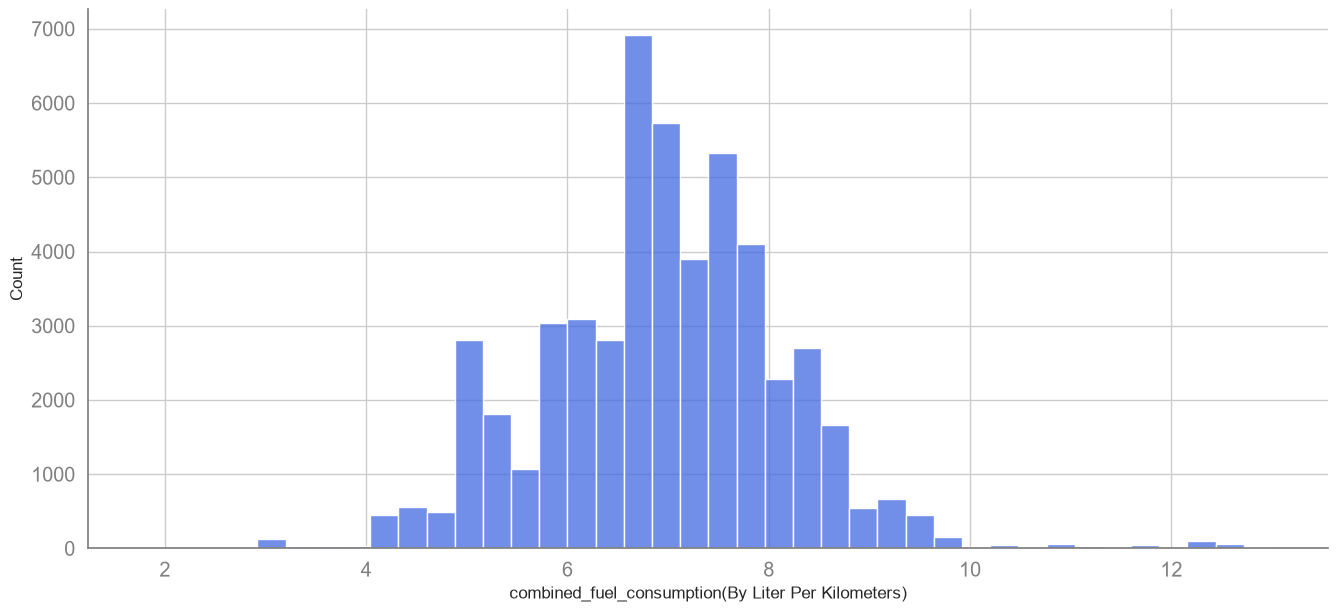

In [44]:
fig , ax = plt.subplots(figsize=(16,7))

sns.histplot(
    data=data,
    x="combined_fuel_consumption(By Liter Per Kilometers)",
    bins=40,  
    color="royalblue",  
)

ax.spines[["right", "top"]].set_visible(False)
ax.spines[['left', 'bottom']].set_color('gray')

ax.tick_params(axis="x", colors="gray", labelsize="large")
ax.tick_params(axis="y", colors="gray", labelsize="large")

plt.show()

In [45]:
mean = data['combined_fuel_consumption(By Liter Per Kilometers)'].mean()
std = data['combined_fuel_consumption(By Liter Per Kilometers)'].std()

lower_limit = mean - 3 * std
upper_limit = mean + 3 * std

data = data[
    (data['combined_fuel_consumption(By Liter Per Kilometers)'] >= lower_limit) & 
    (data['combined_fuel_consumption(By Liter Per Kilometers)'] <= upper_limit)
]

Unlike other skewed vehicle metrics, the `combined_fuel_consumption` feature follows an approximately normal (Gaussian) distribution.

- **Cleaning Methodology:** Applied the **Three-Sigma Rule ($3\sigma$)** ($\mu \pm 3\sigma$) to detect and remove extreme outliers.
- **Coverage:** In a normal distribution, approximately **99.73%** of data points lie within three standard deviations of the mean, allowing us to safely eliminate anomalous and unrealistic records ($\approx 0.27\%$).

> **Data Cleaning Note:** Outliers were permanently removed from the dataset using the $3\sigma$ threshold to preserve the integrity of the feature's natural distribution.


<br><br>

## StoryTelling

In [46]:
str_columns  = ['title', 'address', 'fuel_type', 'transmission', 
                'authentication_status', 'body_condition', 'body_color', 'interior_color', 'powertrain']

for c in str_columns:
    data[c] = data[c].str.strip()

In [47]:
data.head()

,title,price,year,address,authentication_status,mileage(By km),fuel_type,transmission,body_condition,body_color,interior_color,engine_capacity(By Liter),powertrain,acceleration(By Second),combined_fuel_consumption(By Liter Per Kilometers)
0,هیوندای، توسان,3690000000,1396,تهران / پاسداران,not_authenticated,99500,بنزینی,اتوماتیک,بدون رنگ,سفید,مشکی,2.00,4 سیلندر,11.80,8.30
1,ب ام و، X3,5500000000,1394,تبریز,not_authenticated,72000,بنزینی,اتوماتیک,دو لکه رنگ,قهوه ای,کرم,2.00,4 سیلندر توربوشارژ,6.50,7.30
2,پژو، پارس,600000000,1393,لارستان,not_authenticated,165000,بنزینی,دنده ای,بدون رنگ,سفید,قهوه ای,1.60,4 سیلندر TU5,13.20,7.50
3,پژو، 206 SD,670000000,1396,تبریز,not_authenticated,93000,بنزینی,دنده ای,بدون رنگ,نقره ای,مشکی,1.60,4 سیلندر TU5,11.40,6.60
4,تویوتا، پرادو دو در,4600000000,1385,تهران / شهید مطهری,not_authenticated,289000,بنزینی,اتوماتیک,بدون رنگ,بژ,کرم,2.09,نامشخص,9.32,5.72


In [48]:
data['brand'] = data['title'].str.split('،').str[0].str.strip()
data['model'] = data['title'].str.split('،').str[1].str.strip()

In [49]:
data[['city', 'location']] = data['address'].str.split('/',expand=True)
data['location'] = data['location'].replace(np.nan,'نامشخص')

In [50]:
data['price_per_mileage'] = np.log1p(data['price'] // (data['mileage(By km)'] + 1))
data['acceleration_displacement_ratio'] = ( data['acceleration(By Second)'] * data['engine_capacity(By Liter)'] ).round(2)
data['agility_index'] = 1 / data['acceleration_displacement_ratio'] 
data['estimated_fuel_burned'] = ( data['mileage(By km)'] * data['combined_fuel_consumption(By Liter Per Kilometers)'] ) // 100
data['freshness_score'] = ( 1 / ( (data['mileage(By km)'] + 1) * data['combined_fuel_consumption(By Liter Per Kilometers)'] ) * 1000000 ).round(2)

In [51]:
current_year = jdatetime.datetime.now().year
data['car_age'] = current_year - data['year']
data['annual_mileage'] = ( data['mileage(By km)'] / (data['car_age'] + 1) ).round(2)
data['usage_intensity_ratio'] = ( data['annual_mileage'] / 20000 ).round(2)
data['modern_acceleration_index'] = ( data['acceleration(By Second)'] / (data['car_age'] + 1) ).round(2)

In [52]:
conditions = [ data['engine_capacity(By Liter)'] <= 1.5 ,
              (data['engine_capacity(By Liter)'] > 1.5) & (data['engine_capacity(By Liter)'] <= 2),
              data['engine_capacity(By Liter)'] > 2 ]
choices = ['Small', 'Medium', 'Large']

data['engine_class'] = np.select(conditions, choices, default='Unknown')

In [53]:
data.head()

,title,price,year,address,authentication_status,mileage(By km),fuel_type,transmission,body_condition,body_color,interior_color,engine_capacity(By Liter),powertrain,acceleration(By Second),combined_fuel_consumption(By Liter Per Kilometers),brand,model,city,location,price_per_mileage,acceleration_displacement_ratio,agility_index,estimated_fuel_burned,freshness_score,car_age,annual_mileage,usage_intensity_ratio,modern_acceleration_index,engine_class
0,هیوندای، توسان,3690000000,1396,تهران / پاسداران,not_authenticated,99500,بنزینی,اتوماتیک,بدون رنگ,سفید,مشکی,2.00,4 سیلندر,11.80,8.30,هیوندای,توسان,تهران,پاسداران,10.520995,23.60,0.042373,8258.0,1.21,9,9950.00,0.50,1.18,Medium
1,ب ام و، X3,5500000000,1394,تبریز,not_authenticated,72000,بنزینی,اتوماتیک,دو لکه رنگ,قهوه ای,کرم,2.00,4 سیلندر توربوشارژ,6.50,7.30,ب ام و,X3,تبریز,نامشخص,11.243581,13.00,0.076923,5256.0,1.90,11,6000.00,0.30,0.54,Medium
2,پژو، پارس,600000000,1393,لارستان,not_authenticated,165000,بنزینی,دنده ای,بدون رنگ,سفید,قهوه ای,1.60,4 سیلندر TU5,13.20,7.50,پژو,پارس,لارستان,نامشخص,8.198914,21.12,0.047348,12375.0,0.81,12,12692.31,0.63,1.02,Medium
3,پژو، 206 SD,670000000,1396,تبریز,not_authenticated,93000,بنزینی,دنده ای,بدون رنگ,نقره ای,مشکی,1.60,4 سیلندر TU5,11.40,6.60,پژو,206 SD,تبریز,نامشخص,8.882531,18.24,0.054825,6138.0,1.63,9,9300.00,0.46,1.14,Medium
4,تویوتا، پرادو دو در,4600000000,1385,تهران / شهید مطهری,not_authenticated,289000,بنزینی,اتوماتیک,بدون رنگ,بژ,کرم,2.09,نامشخص,9.32,5.72,تویوتا,پرادو دو در,تهران,شهید مطهری,9.675143,19.48,0.051335,16530.0,0.60,20,13761.90,0.69,0.44,Large


<br><br>

## EDA

In [54]:
data.shape

(50672, 29)

In [55]:
data.drop_duplicates().shape

(32418, 29)

In [56]:
data = data.drop_duplicates()

#### About 18,254 rows were duplicated whether has cleaned .

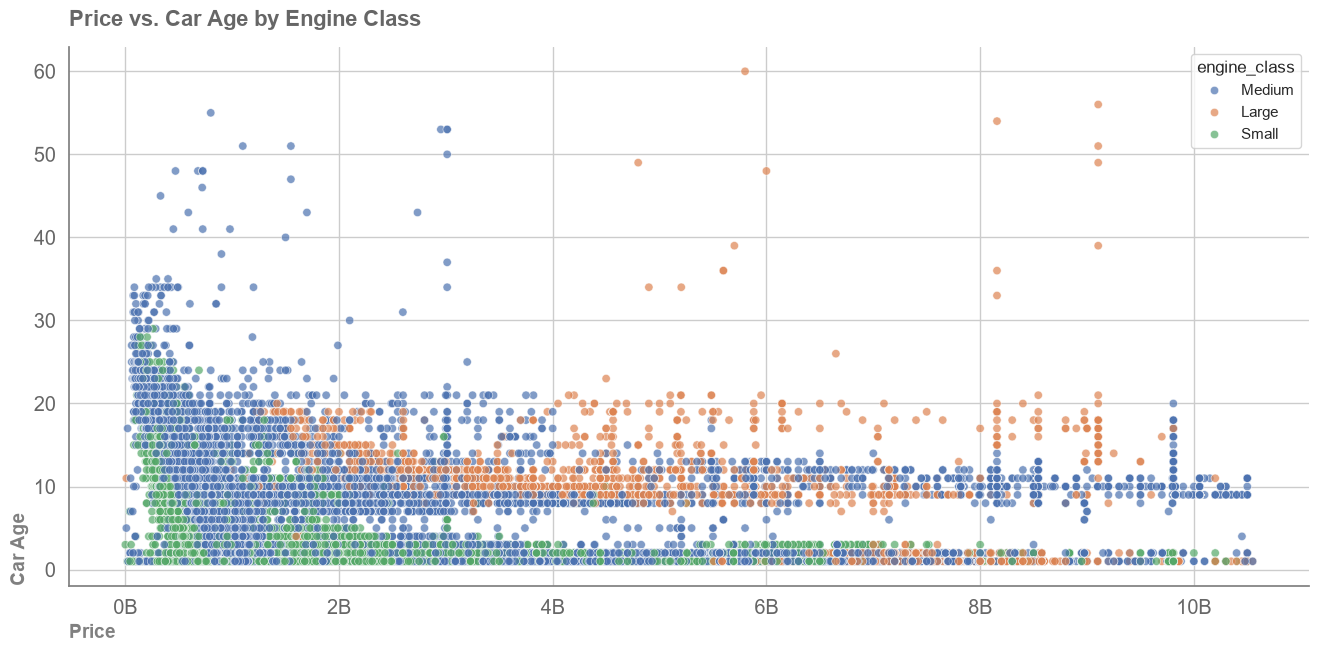

In [57]:
fig , ax = plt.subplots(figsize=(16,7))

sns.scatterplot(data=data, ax=ax,x='price', y='car_age' , hue='engine_class' , alpha=0.7, palette='deep')

ax.spines[['right','top']].set_visible(False)
ax.spines[['left','bottom']].set_color('gray')

ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1e9:.0f}B'))
ax.tick_params(axis='x', colors='#666666', labelsize='large')
ax.tick_params(axis='y', colors='#666666', labelsize='large')

ax.set_title('Price vs. Car Age by Engine Class', fontsize=16, weight='bold', color='#666666', loc='left', pad=15)
ax.set_xlabel('Price', loc='left', color='gray', fontsize=14, weight='bold')
ax.set_ylabel('Car Age', loc='bottom', color='gray', fontsize=14, weight='bold')


plt.show()

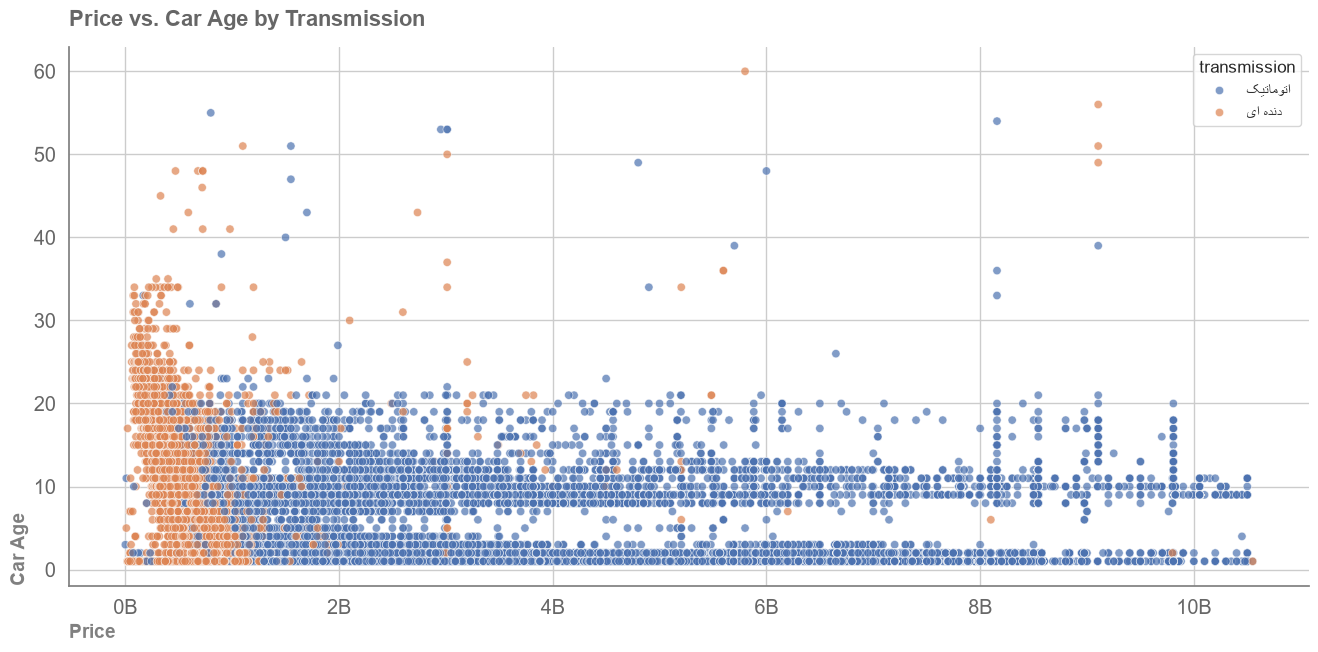

In [58]:
fig , ax = plt.subplots(figsize=(16,7))

sns.scatterplot(data=data, ax=ax,x='price', y='car_age' , hue='transmission' , alpha=0.7, palette='deep')

ax.spines[['right','top']].set_visible(False)
ax.spines[['left','bottom']].set_color('gray')

ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1e9:.0f}B'))
ax.tick_params(axis='x', colors='#666666', labelsize='large')
ax.tick_params(axis='y', colors='#666666', labelsize='large')

ax.set_title('Price vs. Car Age by Transmission', fontsize=16, weight='bold', color='#666666', loc='left', pad=15)
ax.set_xlabel('Price', loc='left', color='gray', fontsize=14, weight='bold')
ax.set_ylabel('Car Age', loc='bottom', color='gray', fontsize=14, weight='bold')


plt.show()

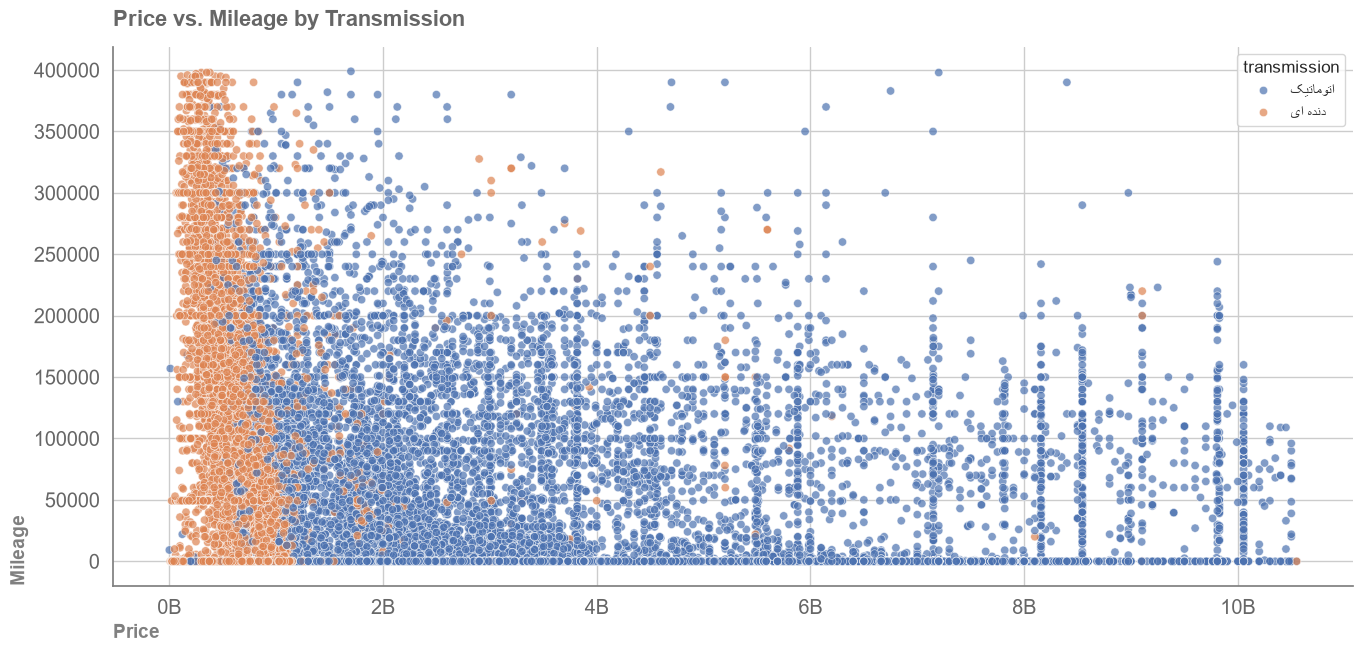

In [59]:
fig , ax = plt.subplots(figsize=(16,7))

sns.scatterplot(data=data, ax=ax,x='price', y='mileage(By km)' , hue='transmission' , alpha=0.7, palette='deep')

ax.spines[['right','top']].set_visible(False)
ax.spines[['left','bottom']].set_color('gray')

ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1e9:.0f}B'))
ax.tick_params(axis='x', colors='#666666', labelsize='large')
ax.tick_params(axis='y', colors='#666666', labelsize='large')

ax.set_title('Price vs. Mileage by Transmission', fontsize=16, weight='bold', color='#666666', loc='left', pad=15)
ax.set_xlabel('Price', loc='left', color='gray', fontsize=14, weight='bold')
ax.set_ylabel('Mileage', loc='bottom', color='gray', fontsize=14, weight='bold')


plt.show()

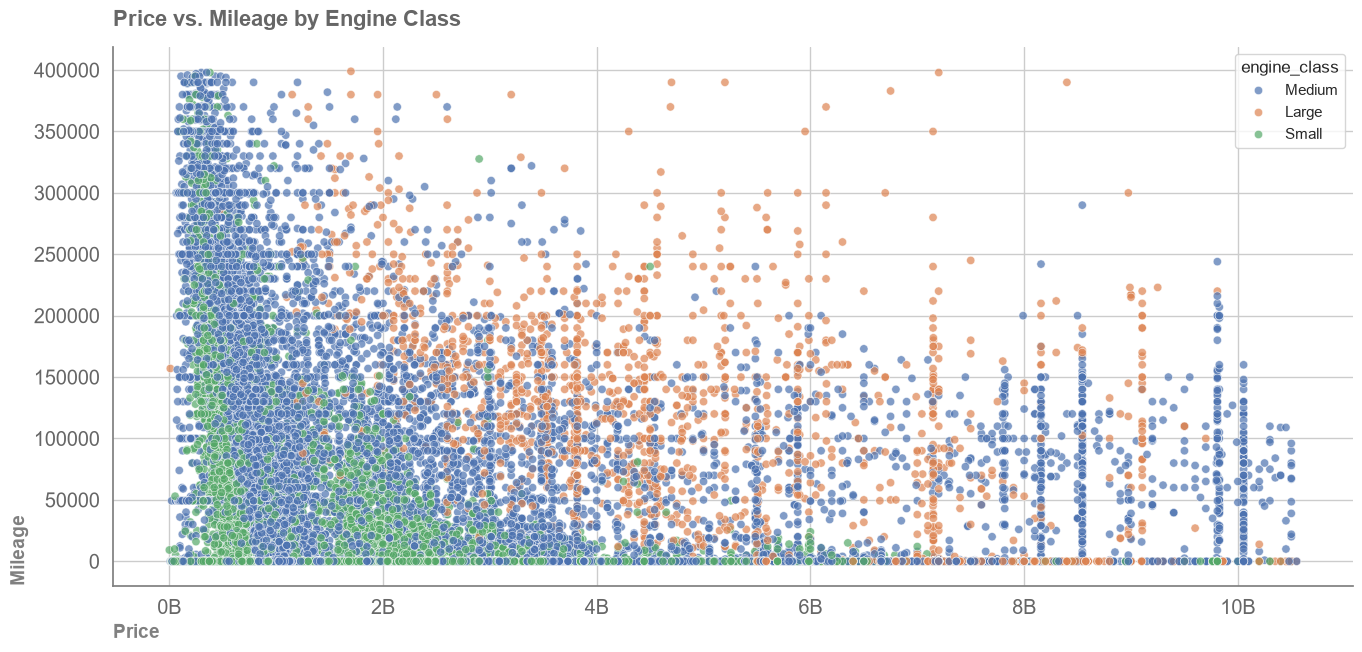

In [60]:
fig , ax = plt.subplots(figsize=(16,7))

sns.scatterplot(data=data, ax=ax,x='price', y='mileage(By km)' , hue='engine_class' , alpha=0.7, palette='deep')

ax.spines[['right','top']].set_visible(False)
ax.spines[['left','bottom']].set_color('gray')

ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1e9:.0f}B'))
ax.tick_params(axis='x', colors='#666666', labelsize='large')
ax.tick_params(axis='y', colors='#666666', labelsize='large')

ax.set_title('Price vs. Mileage by Engine Class', fontsize=16, weight='bold', color='#666666', loc='left', pad=15)
ax.set_xlabel('Price', loc='left', color='gray', fontsize=14, weight='bold')
ax.set_ylabel('Mileage', loc='bottom', color='gray', fontsize=14, weight='bold')


plt.show()

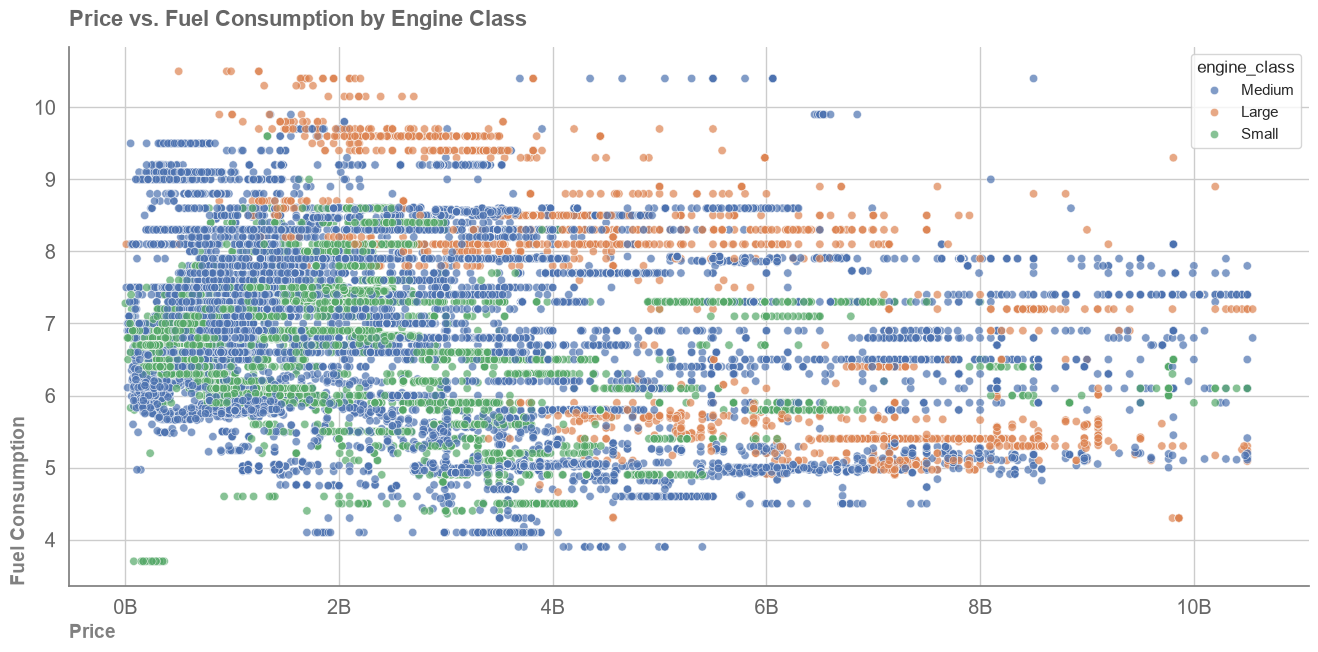

In [61]:
fig , ax = plt.subplots(figsize=(16,7))

sns.scatterplot(data=data, ax=ax,x='price', y='combined_fuel_consumption(By Liter Per Kilometers)' , hue='engine_class' , alpha=0.7, palette='deep')

ax.spines[['right','top']].set_visible(False)
ax.spines[['left','bottom']].set_color('gray')

ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1e9:.0f}B'))
ax.tick_params(axis='x', colors='#666666', labelsize='large')
ax.tick_params(axis='y', colors='#666666', labelsize='large')

ax.set_title('Price vs. Fuel Consumption by Engine Class', fontsize=16, weight='bold', color='#666666', loc='left', pad=15)
ax.set_xlabel('Price', loc='left', color='gray', fontsize=14, weight='bold')
ax.set_ylabel('Fuel Consumption', loc='bottom', color='gray', fontsize=14, weight='bold')


plt.show()

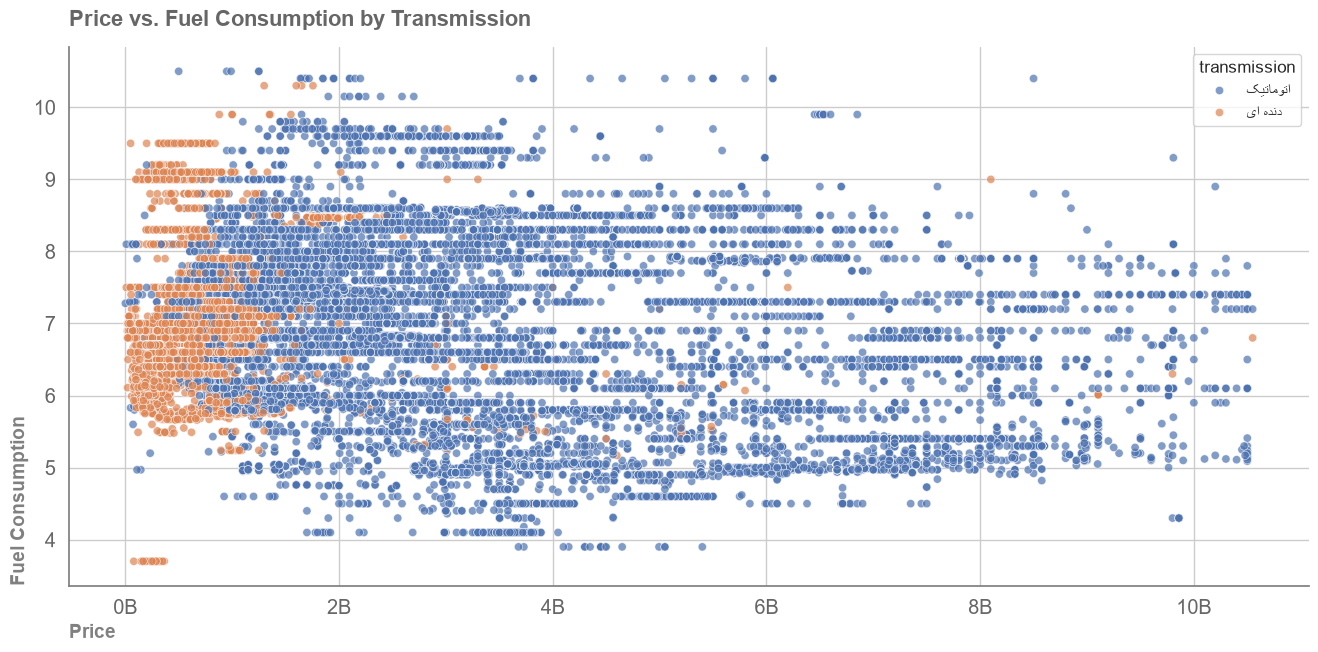

In [62]:
fig , ax = plt.subplots(figsize=(16,7))

sns.scatterplot(data=data, ax=ax,x='price', y='combined_fuel_consumption(By Liter Per Kilometers)' , hue='transmission' , alpha=0.7, palette='deep')

ax.spines[['right','top']].set_visible(False)
ax.spines[['left','bottom']].set_color('gray')

ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1e9:.0f}B'))
ax.tick_params(axis='x', colors='#666666', labelsize='large')
ax.tick_params(axis='y', colors='#666666', labelsize='large')

ax.set_title('Price vs. Fuel Consumption by Transmission', fontsize=16, weight='bold', color='#666666', loc='left', pad=15)
ax.set_xlabel('Price', loc='left', color='gray', fontsize=14, weight='bold')
ax.set_ylabel('Fuel Consumption', loc='bottom', color='gray', fontsize=14, weight='bold')


plt.show()

In [63]:
data.columns

Index(['title', 'price', 'year', 'address', 'authentication_status',
       'mileage(By km)', 'fuel_type', 'transmission', 'body_condition',
       'body_color', 'interior_color', 'engine_capacity(By Liter)',
       'powertrain', 'acceleration(By Second)',
       'combined_fuel_consumption(By Liter Per Kilometers)', 'brand', 'model',
       'city', 'location', 'price_per_mileage',
       'acceleration_displacement_ratio', 'agility_index',
       'estimated_fuel_burned', 'freshness_score', 'car_age', 'annual_mileage',
       'usage_intensity_ratio', 'modern_acceleration_index', 'engine_class'],
      dtype='str')

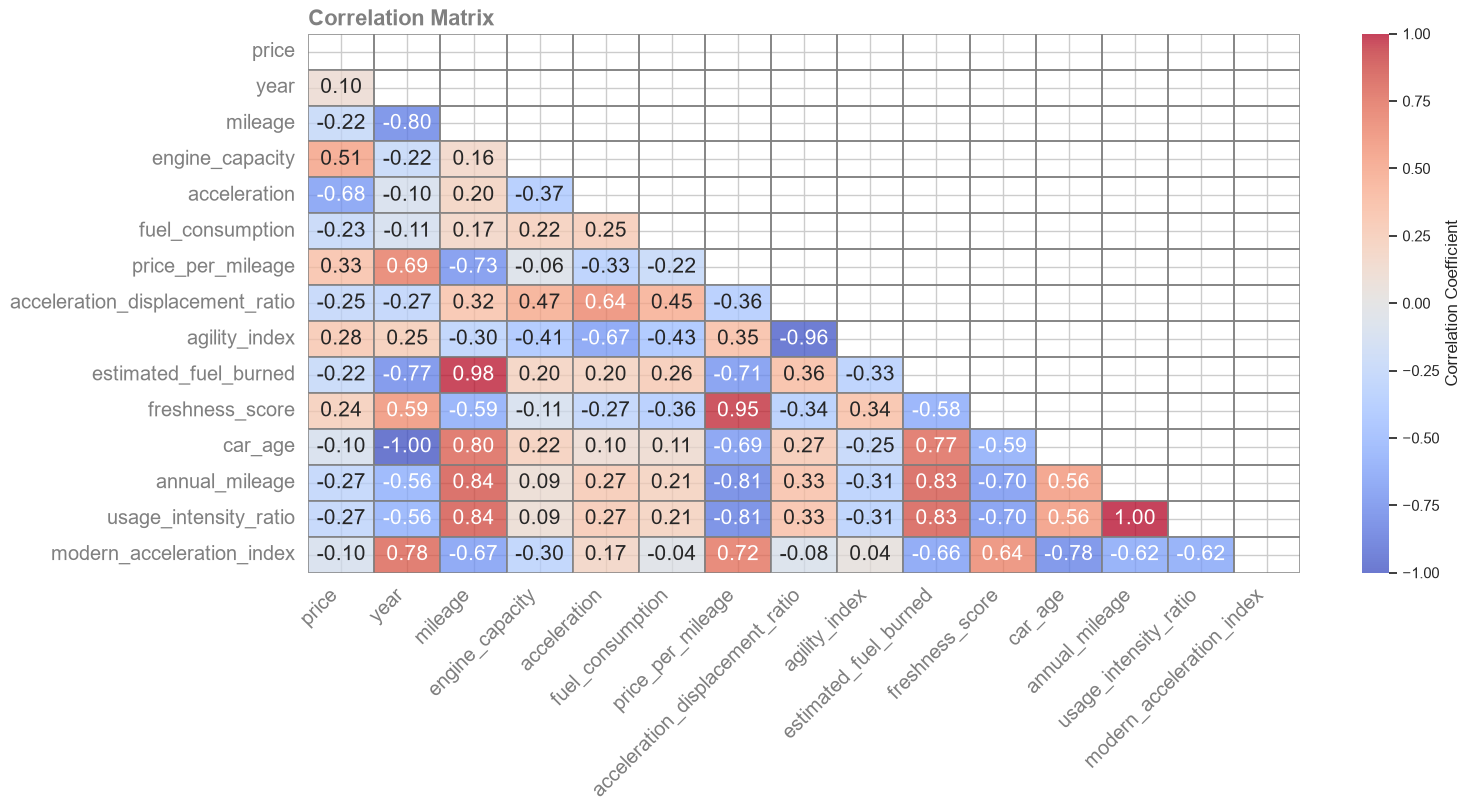

In [64]:
corr_matrix = data.corr(numeric_only=True).rename(columns={'mileage(By km)':'mileage',
                                                        'engine_capacity(By Liter)':'engine_capacity',
                                                        'acceleration(By Second)':'acceleration',
                                                        'combined_fuel_consumption(By Liter Per Kilometers)': 'fuel_consumption'},
                                                  index={'mileage(By km)':'mileage',
                                                        'engine_capacity(By Liter)':'engine_capacity',
                                                        'acceleration(By Second)':'acceleration',
                                                        'combined_fuel_consumption(By Liter Per Kilometers)': 'fuel_consumption'})

fig , ax = plt.subplots(figsize=(16,7))

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(data=corr_matrix, 
            annot=True, 
            mask=mask,
            fmt='.2f', 
            cmap='coolwarm', 
            annot_kws={'size':15},
            linewidths=0.25,
            linecolor='gray',
            vmin=-1, 
            vmax=1,
            center=0, 
            alpha=0.75,
            cbar=True,
            cbar_kws={'label':'Correlation Coefficient','orientation': 'vertical'},
            ax=ax )


ax.spines[["right", "top"]].set_visible(False)
ax.spines[['left', 'bottom']].set_color('gray')

ax.tick_params(axis="x", colors="gray", labelsize="large")
ax.tick_params(axis="y", colors="gray", labelsize="large")
plt.xticks(rotation=45, ha='right')

ax.set_title('Correlation Matrix',weight='bold',color='gray',fontsize=16, loc='left')
ax.set_xlabel('')
ax.set_ylabel('')

plt.show()

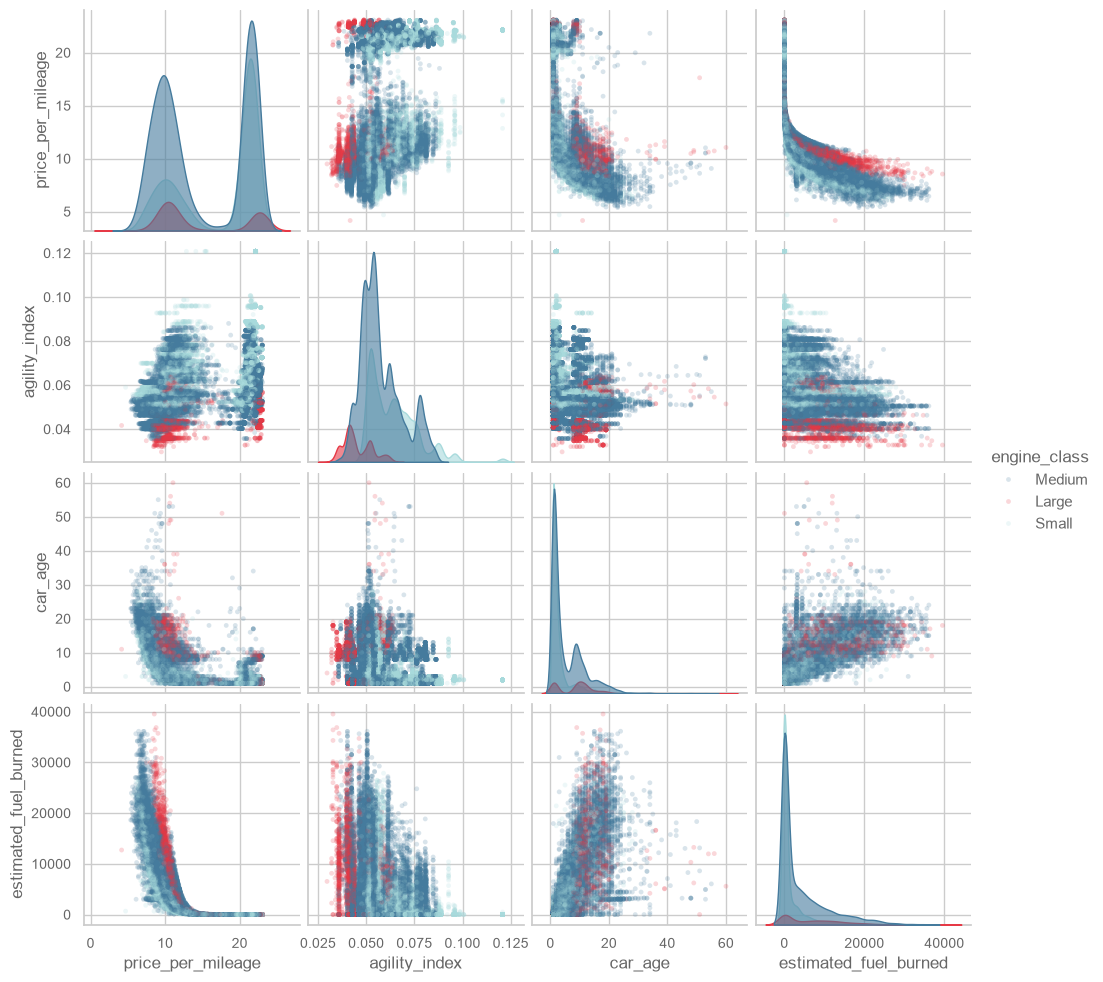

In [65]:
g = sns.pairplot(
    data=data,
    vars=['price_per_mileage', 'agility_index', 'car_age', 'estimated_fuel_burned'],
    hue='engine_class',
    plot_kws={'alpha': 0.2, 's': 12, 'edgecolor': 'none'}, 
    diag_kws={'alpha': 0.6},
  #  plot_kws={'alpha': 0.3, 's': 10},
    palette={ 'Small': '#A8DADC', 'Medium': '#457B9D', 'Large': '#E63946'}
)

gray_color = '#666666'
for ax in g.axes.flat:
    if ax is not None:
        ax.tick_params(axis='both', colors=gray_color, labelsize='small')
        
        ax.xaxis.label.set_color(gray_color)
        ax.yaxis.label.set_color(gray_color)
        
        for spine in ax.spines.values():
            spine.set_color('#CCCCCC') 

g._legend.get_title().set_color(gray_color)
for text in g._legend.get_texts():
    text.set_color(gray_color)

plt.show()

<br><br>

## Save To CSV

In [68]:
data.to_csv("cleaned_bama.csv", index=False)